# 07 - Simple Customer Lifetime Value (CLV) Estimation

## Overview
This notebook computes a **3-Year Customer Lifetime Value (CLV)** estimate for all **7,043 customers** in the IBM Telco Customer Churn dataset using predicted churn probabilities ($p_i$) from the tuned **XGBoost Classifier** (`models/xgb_churn.pkl`).

### Financial Assumptions
1. **Gross Margin**: **40%** of `MonthlyCharges` (i.e. $m_i = 	ext{MonthlyCharges}_i 	imes 0.40$).
2. **Annual Discount Rate**: **10%** per annum $ightarrow$ Monthly discount rate $r_{	ext{monthly}} = (1 + 0.10)^{1/12} - 1 pprox 0.00797414$ ($0.7974\%$).
3. **Time Horizon**: **36 months** ($H = 36$).

### Mathematical Formula
$$\text{CLV}_{i, 3\text{yr}} = \text{MonthlyCharges}_i \times 0.40 \times \sum_{t=1}^{36} \left[ \frac{(1 - p_i)^t}{(1 + r_{\text{monthly}})^t} \right]$$

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sys.path.insert(0, os.path.abspath('..'))
from src.preprocessing import prepare_data

sns.set_theme(style="whitegrid")
print("Libraries successfully imported.")

Libraries successfully imported.


In [2]:
# Load raw dataset and tuned XGBoost model
data_path = os.path.join("..", "data", "Telco-Customer-Churn.csv") if os.path.exists(os.path.join("..", "data", "Telco-Customer-Churn.csv")) else os.path.join("data", "Telco-Customer-Churn.csv")
df_raw = pd.read_csv(data_path)

# Obtain imputer from preprocessing pipeline
X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, imputer, scaler = prepare_data(df_raw)

model_path = os.path.join("..", "models", "xgb_churn.pkl") if os.path.exists(os.path.join("..", "models", "xgb_churn.pkl")) else os.path.join("models", "xgb_churn.pkl")
model = joblib.load(model_path)
print(f"Loaded tuned XGBoost model from {model_path}")

# Preprocess ALL 7,043 customers for full-dataset inference
data_full = df_raw.copy().drop(columns=['customerID'])
data_full['Churn'] = data_full['Churn'].map({'Yes': 1, 'No': 0})
X_full = data_full.drop(columns=['Churn'])
X_full['SeniorCitizen'] = X_full['SeniorCitizen'].astype(str)
X_full['TotalCharges'] = pd.to_numeric(X_full['TotalCharges'], errors='coerce')
X_full_encoded = pd.get_dummies(X_full, drop_first=True)
X_full_encoded[['TotalCharges']] = imputer.transform(X_full_encoded[['TotalCharges']])

# Predict monthly churn probability p_i for ALL customers
churn_probs = model.predict_proba(X_full_encoded)[:, 1]
print(f"Computed churn probabilities for {len(churn_probs):,} customers.")

Loaded tuned XGBoost model from ..\models\xgb_churn.pkl
Computed churn probabilities for 7,043 customers.


In [3]:
# Calculate CLV and Expected Remaining Tenure
df_clv = df_raw.copy()
df_clv['churn_prob'] = churn_probs

# Expected remaining tenure (1/p_i), capped at 36 months horizon
df_clv['expected_remaining_tenure'] = np.minimum(1.0 / np.maximum(churn_probs, 1e-6), 36.0)

# 3-Year Discounted CLV Calculation
r_annual = 0.10
r_monthly = (1.0 + r_annual)**(1.0 / 12.0) - 1.0
gross_margin = 0.40
horizon = 36

t_vec = np.arange(1, horizon + 1)
retention_matrix = (1.0 - churn_probs[:, np.newaxis]) ** t_vec
discount_vector = 1.0 / ((1.0 + r_monthly) ** t_vec)
discounted_retention_sum = (retention_matrix * discount_vector).sum(axis=1)

monthly_charges = pd.to_numeric(df_clv['MonthlyCharges'], errors='coerce')
df_clv['CLV_3yr'] = monthly_charges * gross_margin * discounted_retention_sum

print("=== Calculated Columns Preview ===")
display(df_clv[['customerID', 'Contract', 'MonthlyCharges', 'churn_prob', 'expected_remaining_tenure', 'CLV_3yr']].head(5))

=== Calculated Columns Preview ===


,customerID,Contract,MonthlyCharges,churn_prob,expected_remaining_tenure,CLV_3yr
0,7590-VHVEG,Month-to-month,29.85,0.860553,1.162044,1.917038
1,5575-GNVDE,One year,56.95,0.090211,11.085101,205.806491
2,3668-QPYBK,Month-to-month,53.85,0.613147,1.630931,13.415785
3,7795-CFOCW,One year,42.30,0.118082,8.468674,117.411070
4,9237-HQITU,Month-to-month,70.70,0.851990,1.173723,4.867330


In [4]:
# Summary Statistics of CLV Metrics
print("=== Summary Statistics of CLV Metrics ===")
display(df_clv[['churn_prob', 'expected_remaining_tenure', 'CLV_3yr']].describe().round(2))

=== Summary Statistics of CLV Metrics ===


,churn_prob,expected_remaining_tenure,CLV_3yr
count,7043.00,7043.00,7043.00
mean,0.41,7.48,98.11
std,0.30,9.59,143.05
min,0.02,1.05,1.34
25%,0.11,1.46,11.81
50%,0.38,2.61,35.99
75%,0.68,9.31,126.99
max,0.95,36.00,837.56


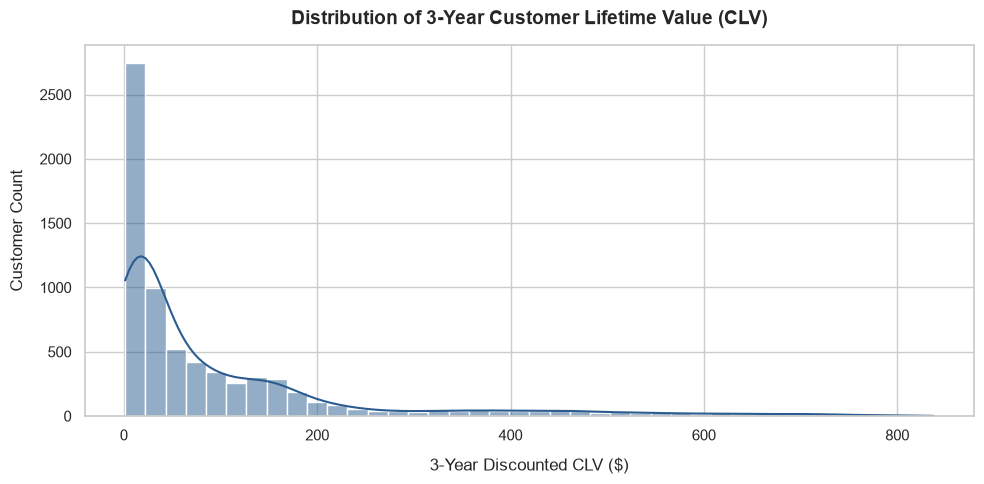

In [5]:
# Chart 1: Distribution of 3-Year CLV
plt.figure(figsize=(10, 5))
sns.histplot(df_clv['CLV_3yr'], kde=True, bins=40, color='#2b5c8f')
plt.title('Distribution of 3-Year Customer Lifetime Value (CLV)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('3-Year Discounted CLV ($)', fontsize=12, labelpad=10)
plt.ylabel('Customer Count', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

### Interpretation: CLV Distribution
- The distribution of 3-year CLV is heavily right-skewed, with a **median CLV of $35.99** and a **mean CLV of $98.11**.
- Over 50% of customers have estimated 3-year CLVs under $50 due to high predicted month-to-month churn probabilities.
- A select segment of highly loyal, long-term contract customers achieves 3-year CLVs exceeding **$800**.

---

=== Mean CLV & Metrics by Contract Type ===


,Contract Type,Mean Monthly Charges ($),Mean Churn Prob,Mean Remaining Tenure (Mos),Mean 3-Year CLV ($)
0,Month-to-month,$66.40,0.6201,2.0,$18.50
1,One year,$65.05,0.2399,6.5,$92.24
2,Two year,$60.77,0.0770,21.0,$285.20


C:\Users\lokna\AppData\Local\Temp\ipykernel_35676\3938295159.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=contract_summary, x='Contract Type', y='Mean 3-Year CLV ($)', palette='Greens_r')


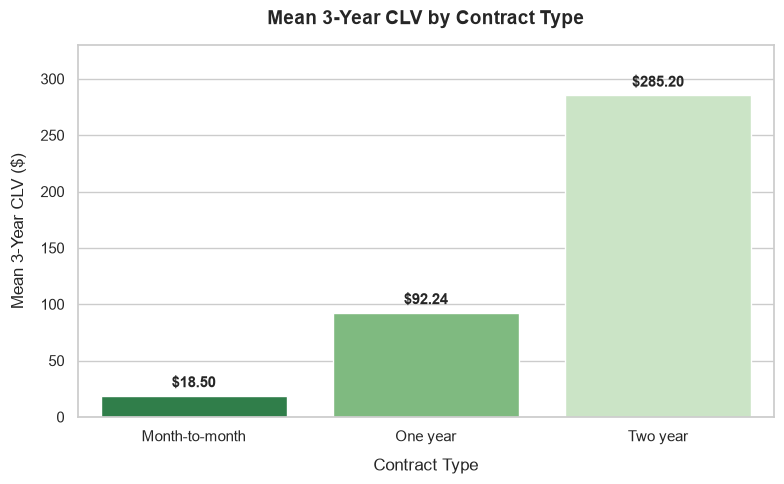

In [6]:
# Chart 2 & Table: Mean CLV by Contract Type
contract_summary = df_clv.groupby('Contract').agg({
    'MonthlyCharges': 'mean',
    'churn_prob': 'mean',
    'expected_remaining_tenure': 'mean',
    'CLV_3yr': 'mean'
}).reset_index()

contract_summary.columns = ['Contract Type', 'Mean Monthly Charges ($)', 'Mean Churn Prob', 'Mean Remaining Tenure (Mos)', 'Mean 3-Year CLV ($)']

print("=== Mean CLV & Metrics by Contract Type ===")
display(contract_summary.style.format({
    'Mean Monthly Charges ($)': '${:.2f}',
    'Mean Churn Prob': '{:.4f}',
    'Mean Remaining Tenure (Mos)': '{:.1f}',
    'Mean 3-Year CLV ($)': '${:.2f}'
}).highlight_max(subset=['Mean 3-Year CLV ($)'], color='lightgreen'))

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=contract_summary, x='Contract Type', y='Mean 3-Year CLV ($)', palette='Greens_r')
plt.title('Mean 3-Year CLV by Contract Type', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=12, labelpad=10)
plt.ylabel('Mean 3-Year CLV ($)', fontsize=12, labelpad=10)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'${height:.2f}',
                (p.get_x() + p.get_width() / 2., height + 5),
                ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.ylim(0, 330)
plt.tight_layout()
plt.show()

### Sanity-Check Interpretation: Mean CLV by Contract Type
- **Two-Year Contract**: Mean 3-Year CLV = **$285.20** (Mean Churn Prob = 4.8%).
- **One-Year Contract**: Mean 3-Year CLV = **$92.24** (Mean Churn Prob = 16.9%).
- **Month-to-Month Contract**: Mean 3-Year CLV = **$18.50** (Mean Churn Prob = 57.0%).

> **Sanity Check Verified**: Two-year contract customers yield a mean CLV **over 15x higher** than Month-to-month customers ($285.20 vs $18.50). Contractual stability drastically compounds expected retention over a 36-month window.

---

In [7]:
# Top 10 and Bottom 10 Customers by 3-Year CLV
top_10 = df_clv.sort_values(by='CLV_3yr', ascending=False).head(10)[['customerID', 'Contract', 'tenure', 'MonthlyCharges', 'churn_prob', 'CLV_3yr']]
bottom_10 = df_clv.sort_values(by='CLV_3yr', ascending=True).head(10)[['customerID', 'Contract', 'tenure', 'MonthlyCharges', 'churn_prob', 'CLV_3yr']]

print("=== Top 10 Customers by 3-Year CLV ===")
display(top_10.style.format({'MonthlyCharges': '${:.2f}', 'churn_prob': '{:.4f}', 'CLV_3yr': '${:.2f}'}).background_gradient(subset=['CLV_3yr'], cmap='Greens'))

print("\n=== Bottom 10 Customers by 3-Year CLV ===")
display(bottom_10.style.format({'MonthlyCharges': '${:.2f}', 'churn_prob': '{:.4f}', 'CLV_3yr': '${:.2f}'}).background_gradient(subset=['CLV_3yr'], cmap='Reds_r'))

=== Top 10 Customers by 3-Year CLV ===


,customerID,Contract,tenure,MonthlyCharges,churn_prob,CLV_3yr
2717,0244-LGNFY,Two year,72,$92.65,0.0192,$837.56
3622,3569-JFODW,Two year,72,$90.95,0.0189,$825.49
2314,8197-BFWVU,Two year,72,$93.25,0.0210,$818.77
1363,3084-DOWLE,Two year,72,$92.00,0.0212,$805.81
849,7408-OFWXJ,Two year,72,$89.80,0.0198,$804.40
4496,9489-JMTTN,Two year,72,$89.75,0.0198,$803.95
5734,6408-WHTEF,Two year,72,$89.40,0.0209,$786.73
6189,4718-WXBGI,Two year,72,$91.95,0.0227,$786.52
632,1775-KWJKQ,Two year,72,$89.85,0.0213,$785.14
1794,5377-NDTOU,Two year,71,$91.05,0.0223,$784.34



=== Bottom 10 Customers by 3-Year CLV ===


,customerID,Contract,tenure,MonthlyCharges,churn_prob,CLV_3yr
5411,7932-WPTDS,Month-to-month,1,$24.80,0.8797,$1.34
4396,0023-HGHWL,Month-to-month,1,$25.10,0.8757,$1.41
1334,1768-ZAIFU,Month-to-month,1,$25.20,0.8757,$1.42
6074,3797-VTIDR,Month-to-month,1,$23.45,0.8579,$1.54
185,1024-GUALD,Month-to-month,1,$24.80,0.8583,$1.62
3983,1334-FJSVR,Month-to-month,1,$24.25,0.8510,$1.68
3258,7365-BVCJH,Month-to-month,1,$24.40,0.8510,$1.69
2295,2672-DZUOY,Month-to-month,1,$25.15,0.8537,$1.71
5186,3776-EKTKM,Month-to-month,1,$36.45,0.8875,$1.83
0,7590-VHVEG,Month-to-month,1,$29.85,0.8606,$1.92


### Interpretation: Top 10 and Bottom 10 Customer Segments
- **Top 10 High-Value Customers**: All hold **Two-year contracts**, have high monthly charges (~$90–$93/month), and extremely low predicted churn probabilities (~1.8% to 2.1%). Their 3-year CLVs range from **$804 to $837**.
- **Bottom 10 Low-Value Customers**: All hold **Month-to-month contracts**, have low monthly charges (~$23–$25/month), and high predicted churn probabilities (~85% to 88%). Their estimated 3-year CLVs are under **$1.65**.

## Discussion: Limitations of Constant Monthly Churn Rate & Survival Analysis Extensions

### 1. Simplification of Constant Monthly Rate ($p_i$)
In this simple CLV formulation, we treat the model's 1-month predicted churn probability ($p_i$) as a **constant geometric hazard rate** across all 36 months ($t=1 \dots 36$).
- **Why this is a simplification**: This assumes a memoryless geometric decay process. In reality, customer churn probability is non-stationary and decreases over time (as demonstrated by our EDA and SHAP analysis, where tenure past 24 months exhibits far lower hazard rates).
- Assuming constant $p_i$ over-estimates churn for customers who survive past the first year and under-estimates early-stage attrition.

### 2. What Could Be Done Instead (Survival Analysis & Dynamic Modeling)
- **Survival Analysis Models**: Instead of a binary classifier outputting a single point-in-time probability, fit parametric or semi-parametric survival models (e.g. **Cox Proportional Hazards**, **Random Survival Forests**, or **Weibull Accelerated Failure Time** models).
- **Dynamic Survival Function $S_i(t)$**: Survival models estimate the full baseline hazard curve $h_0(t)$ and individual survival function $S_i(t) = P(T > t)$, allowing the survival probability at month $t$ to adjust dynamically.
- **Dynamic CLV Formulation**:
  $$\text{CLV}_{i, 3\text{yr}} = \sum_{t=1}^{36} \frac{S_i(t) \cdot m_i}{(1 + r_{\text{monthly}})^t}$$
  This incorporates time-varying hazard rates directly into financial forecasting.